# **YOLOV5**

In [ ]:
!nvidia-smi

Thu Apr  9 10:36:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P0             46W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
import os
HOME = os.getcwd()

%cd {HOME}
!git clone https://github.com/ultralytics/yolov5  # Orijinal YOLOv5 reposu
%cd yolov5
%pip install -r requirements.txt  # YOLOv5 için gerekli tüm paketler

from IPython import display
display.clear_output()

import torch
import utils
display = utils.notebook_init()  # YOLOv5'in kendi check mekanizması

print(f"Kurulum tamamlandı. Çalışma dizini: {os.getcwd()}")

YOLOv5 🚀 v7.0-467-g1d62daa3 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)


Setup complete ✅ (12 CPUs, 83.5 GB RAM, 43.3/235.7 GB disk)
Kurulum tamamlandı. Çalışma dizini: /content/yolov5


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

In [ ]:
!mkdir -p {HOME}/datasets
%cd {HOME}/datasets

/content/datasets


In [ ]:
!pip install roboflow

from roboflow import Roboflow
api_key = "YOUR_ROBOFLOW_API_KEY"
workspace_name = "YOUR_ROBOFLOW_WORKSPACE"
project_slug = "YOUR_PROJECT_SLUG"
if api_key == "YOUR_ROBOFLOW_API_KEY" or workspace_name == "YOUR_ROBOFLOW_WORKSPACE" or project_slug == "YOUR_PROJECT_SLUG":
    raise ValueError("Please add your Roboflow API key, workspace, and project slug before running this cell.")
rf = Roboflow(api_key=api_key)
project = rf.workspace(workspace_name).project(project_slug)
version = project.version(1)
dataset = version.download("yolov5")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Skin-Cancer-1 in yolov5pytorch:: 100%|██████████| 4005/4005 [00:00<00:00, 12676.22it/s]


In [ ]:
import yaml

data_yaml_path = '/content/datasets/Skin-Cancer-1/data.yaml'

with open(data_yaml_path, 'r') as f:
    data = yaml.safe_load(f)


data['train'] = '/content/datasets/Skin-Cancer-1/train/images'
data['val'] = '/content/datasets/Skin-Cancer-1/valid/images'
data['test'] = '/content/datasets/Skin-Cancer-1/test/images'

with open(data_yaml_path, 'w') as f:
    yaml.dump(data, f)

print("data.yaml yolları başarıyla güncellendi!")

data.yaml yolları başarıyla güncellendi!


In [ ]:
%cd {HOME}/yolov5

dataset_path = "/content/datasets/Skin-Cancer-1/data.yaml"

!python train.py \
--img 800 \
--batch 8 \
--epochs 25 \
--data {dataset_path} \
--weights yolov5s.pt \
--cache \
--project {HOME}/runs/train \
--name skin_cancer_yolov5

Görüntülenen çıkış son 5000 satıra kısaltıldı.
  with torch.cuda.amp.autocast(amp):
      11/24      3.37G     0.0279    0.01266     0.0154         21        800:   2% 4/176 [00:00<00:13, 12.94it/s]/content/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
      11/24      3.37G    0.02807    0.01285    0.01532         19        800:   3% 6/176 [00:00<00:12, 13.30it/s]/content/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
      11/24      3.37G    0.02708    0.01335    0.01414         24        800:   3% 6/176 [00:00<00:12, 13.30it/s]/content/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
    

/content


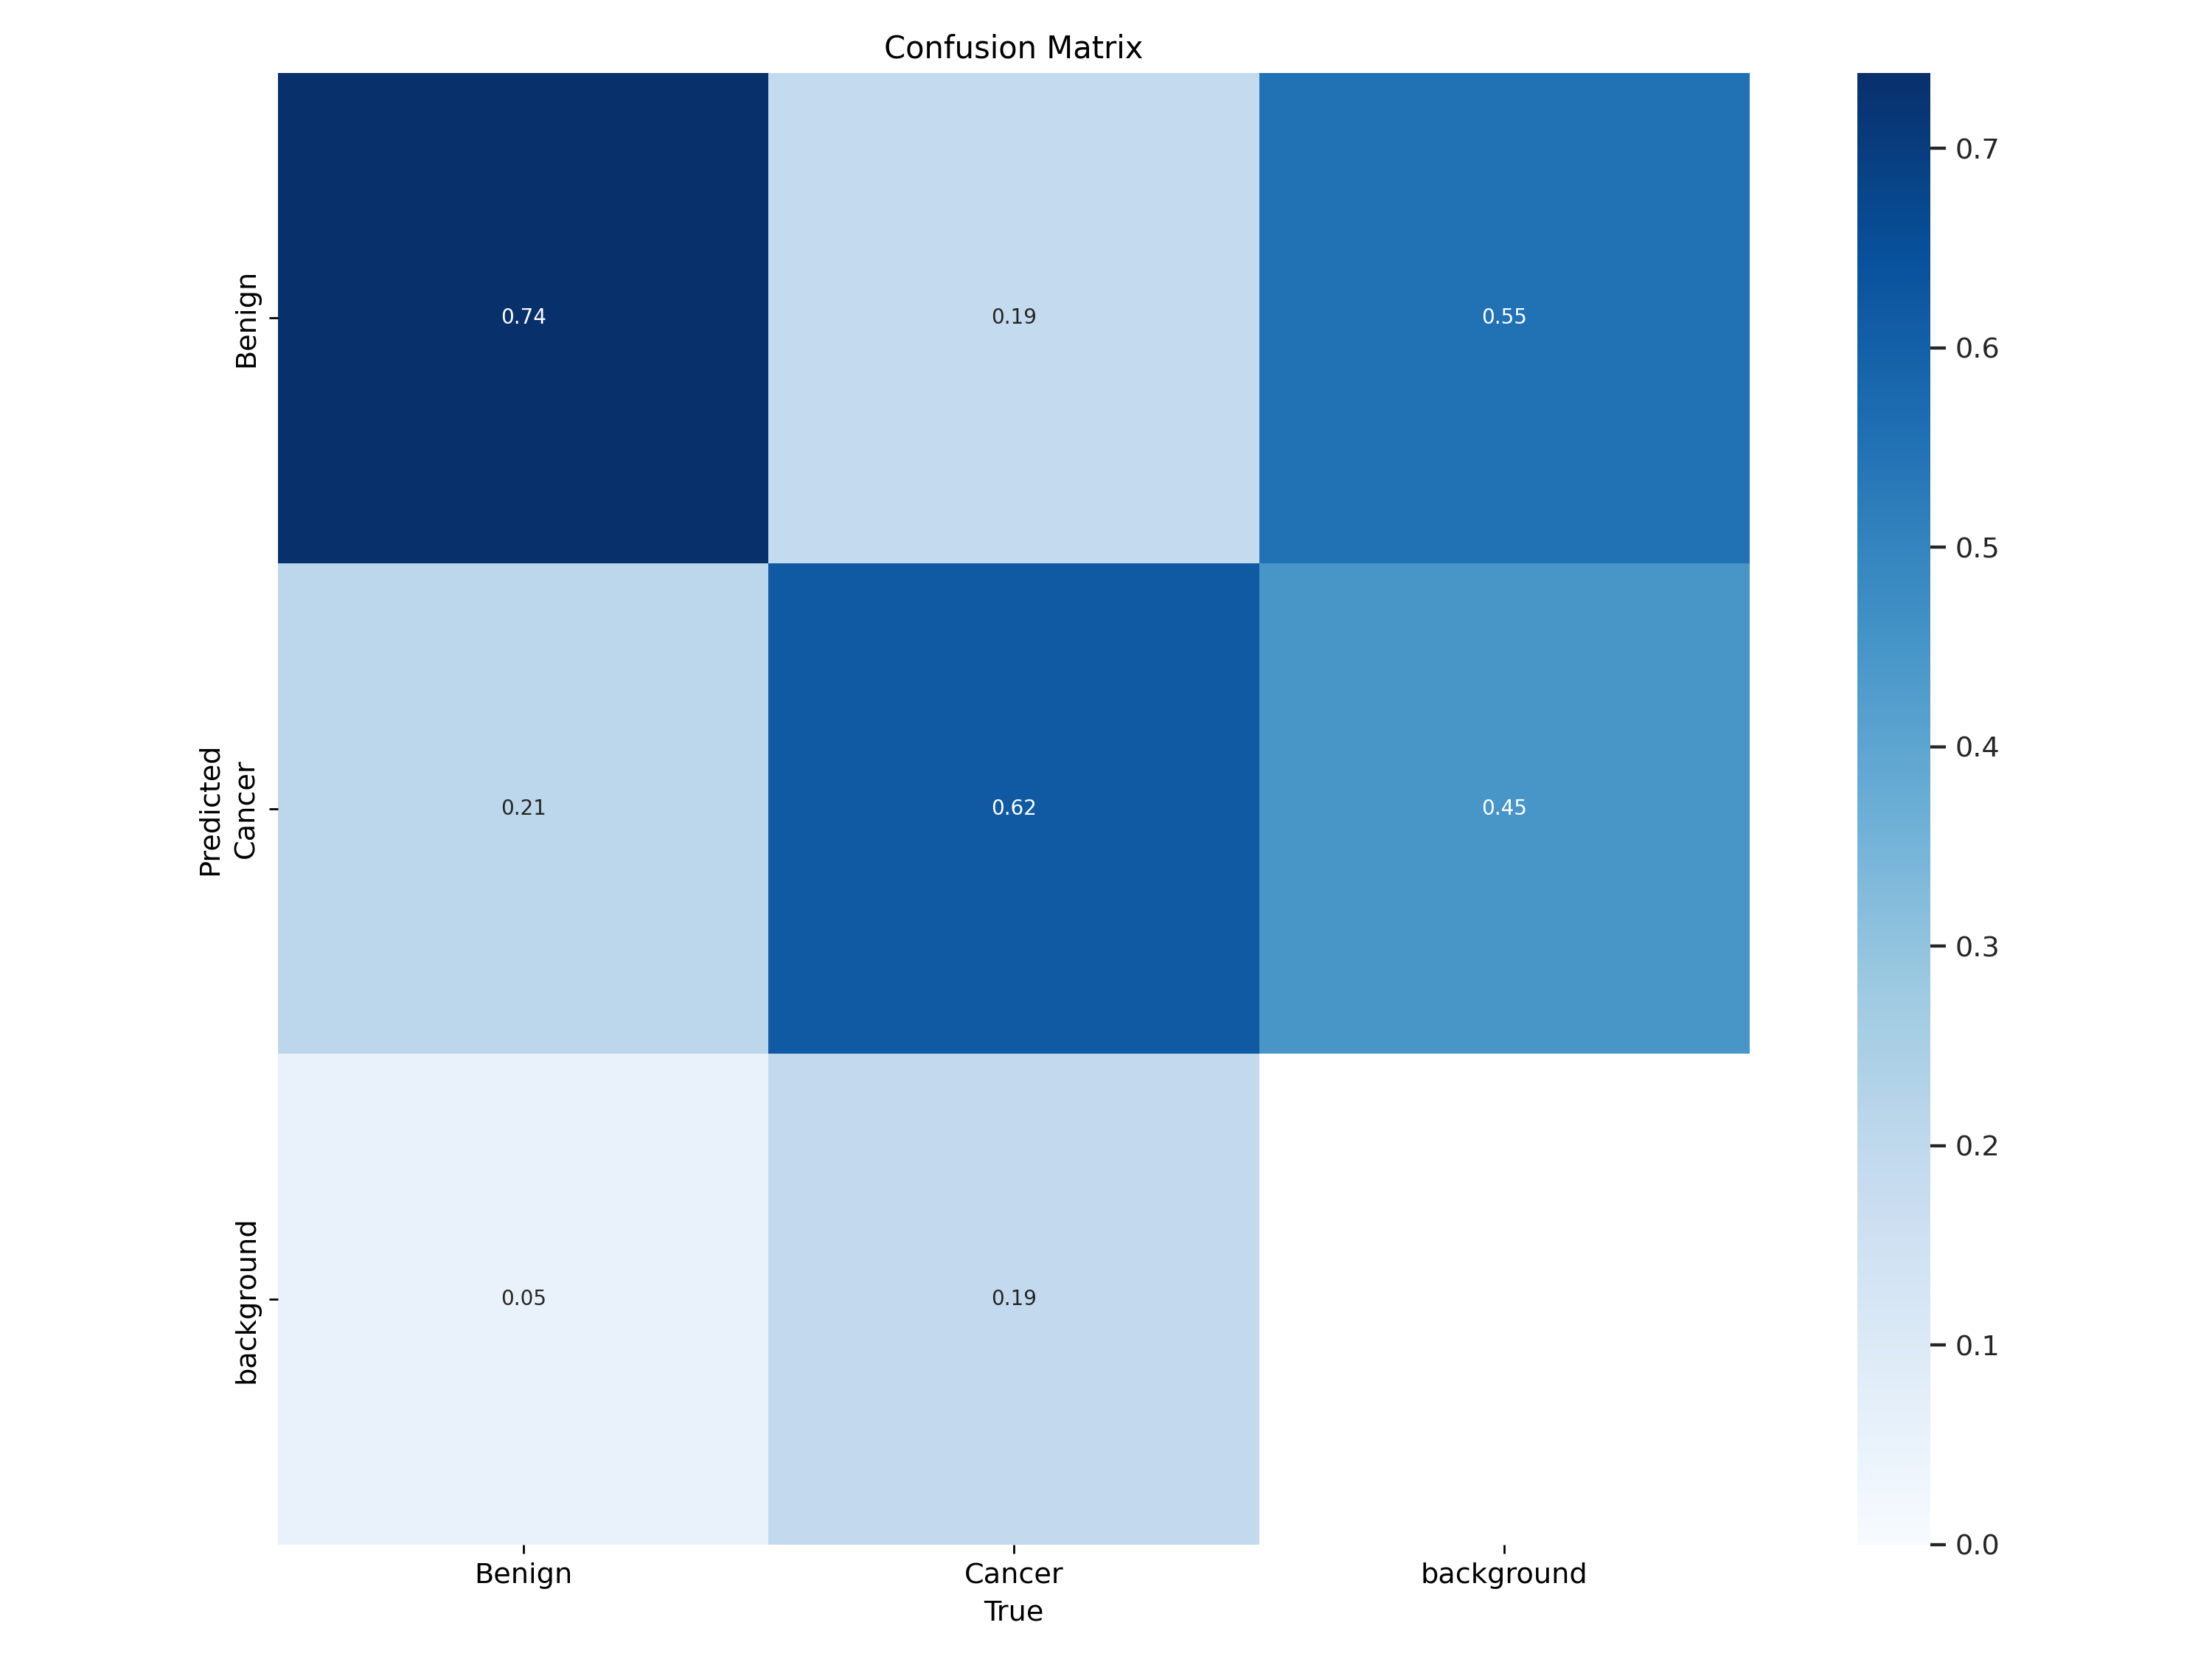

In [ ]:
from IPython.display import Image
%cd {HOME}
Image(filename=f'{HOME}/runs/train/skin_cancer_yolov52/confusion_matrix.png', width=600)

/content


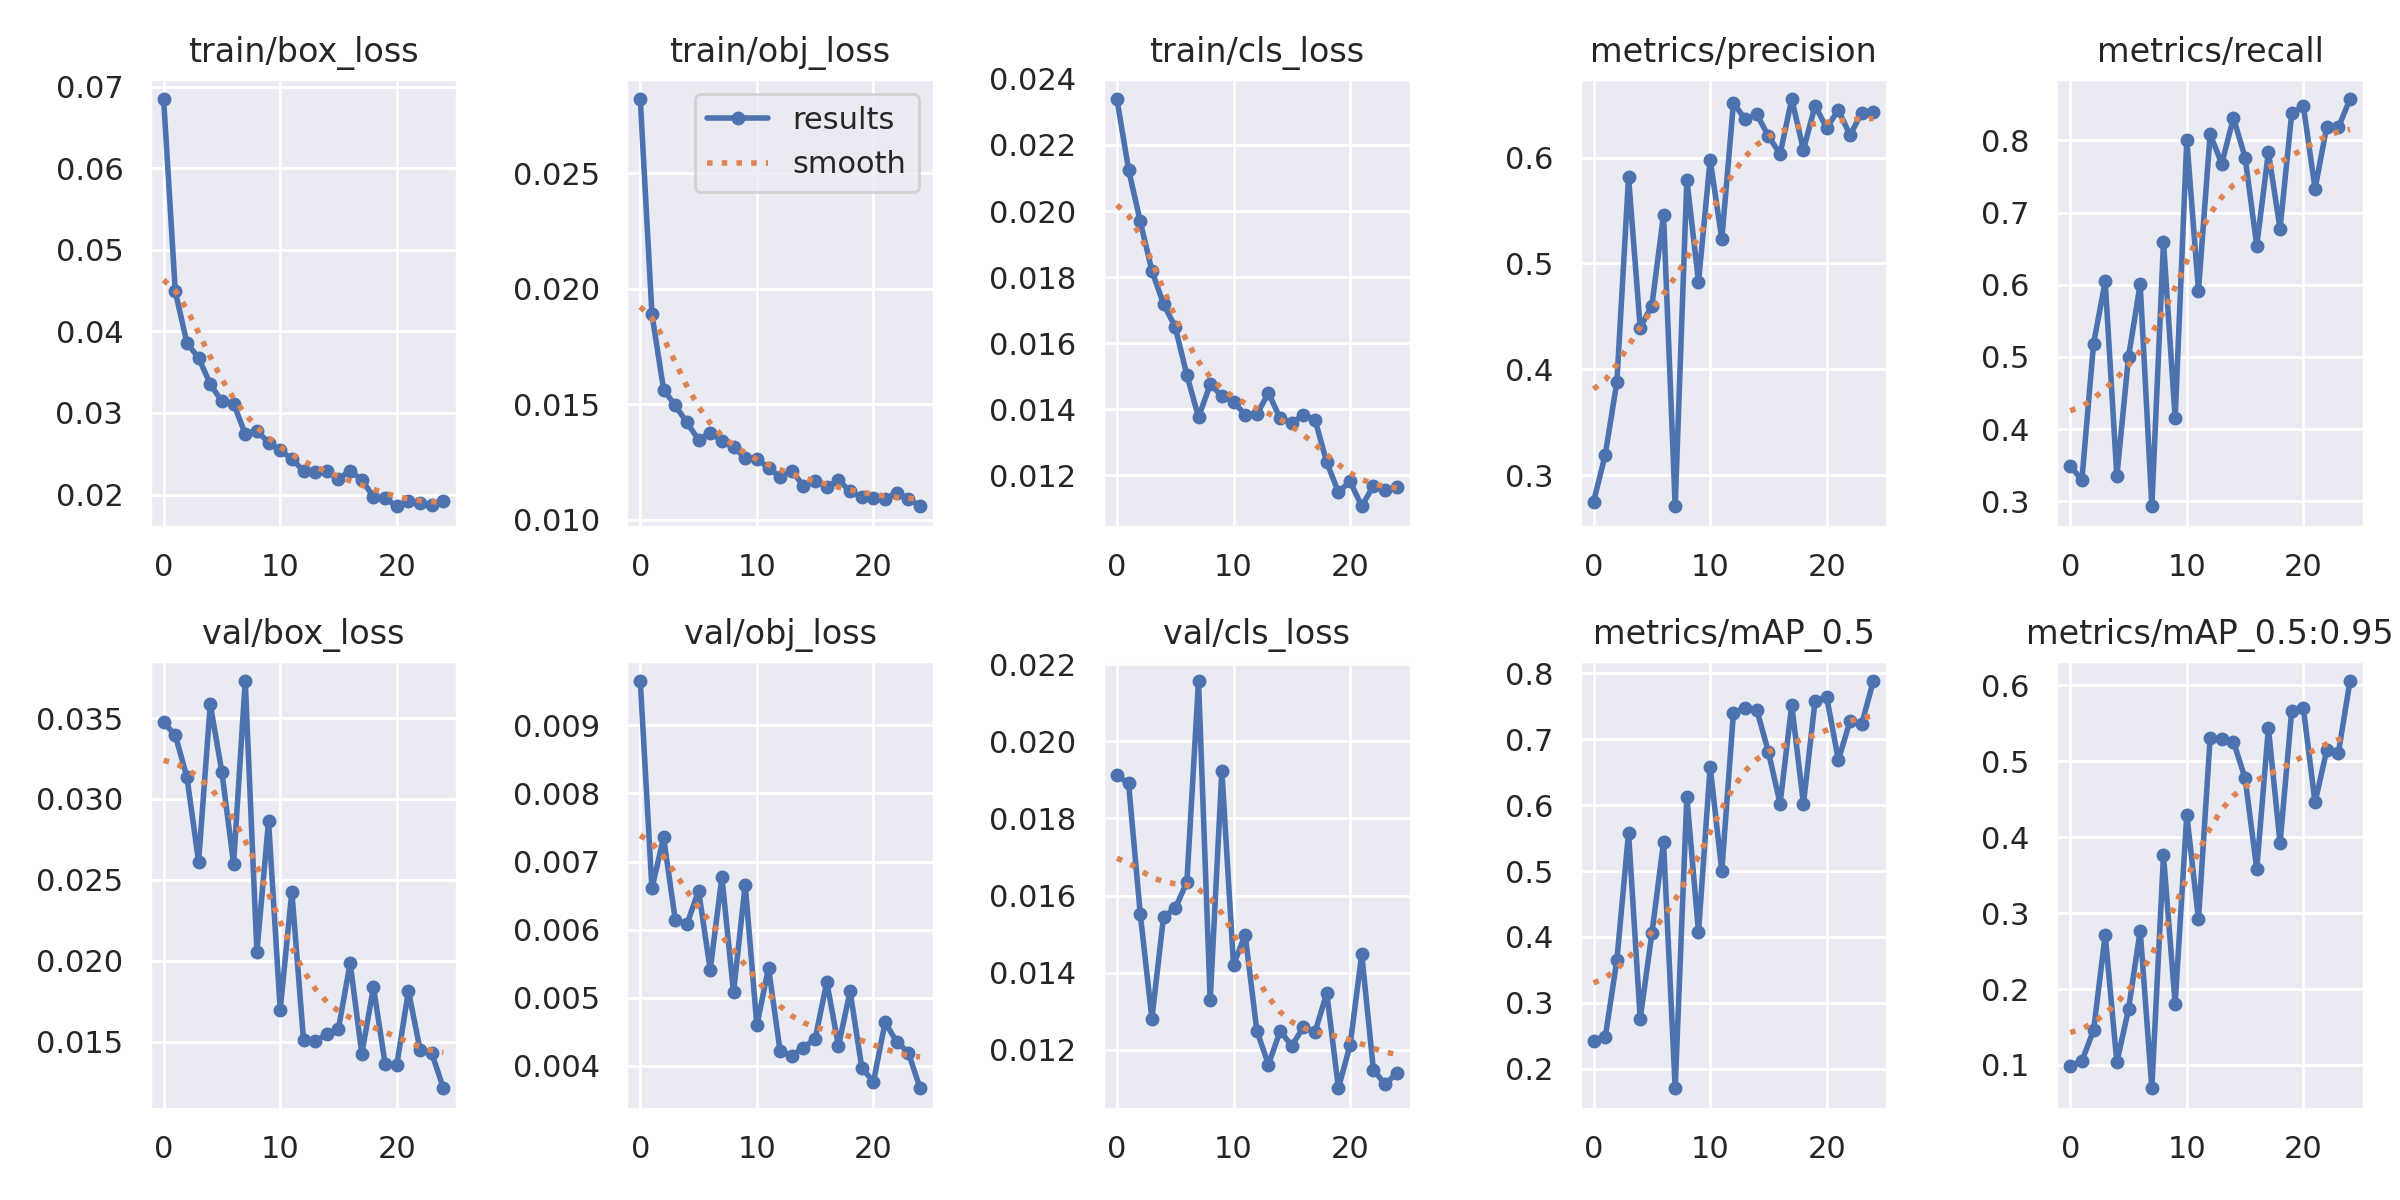

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/train/skin_cancer_yolov52/results.png', width=600)

/content


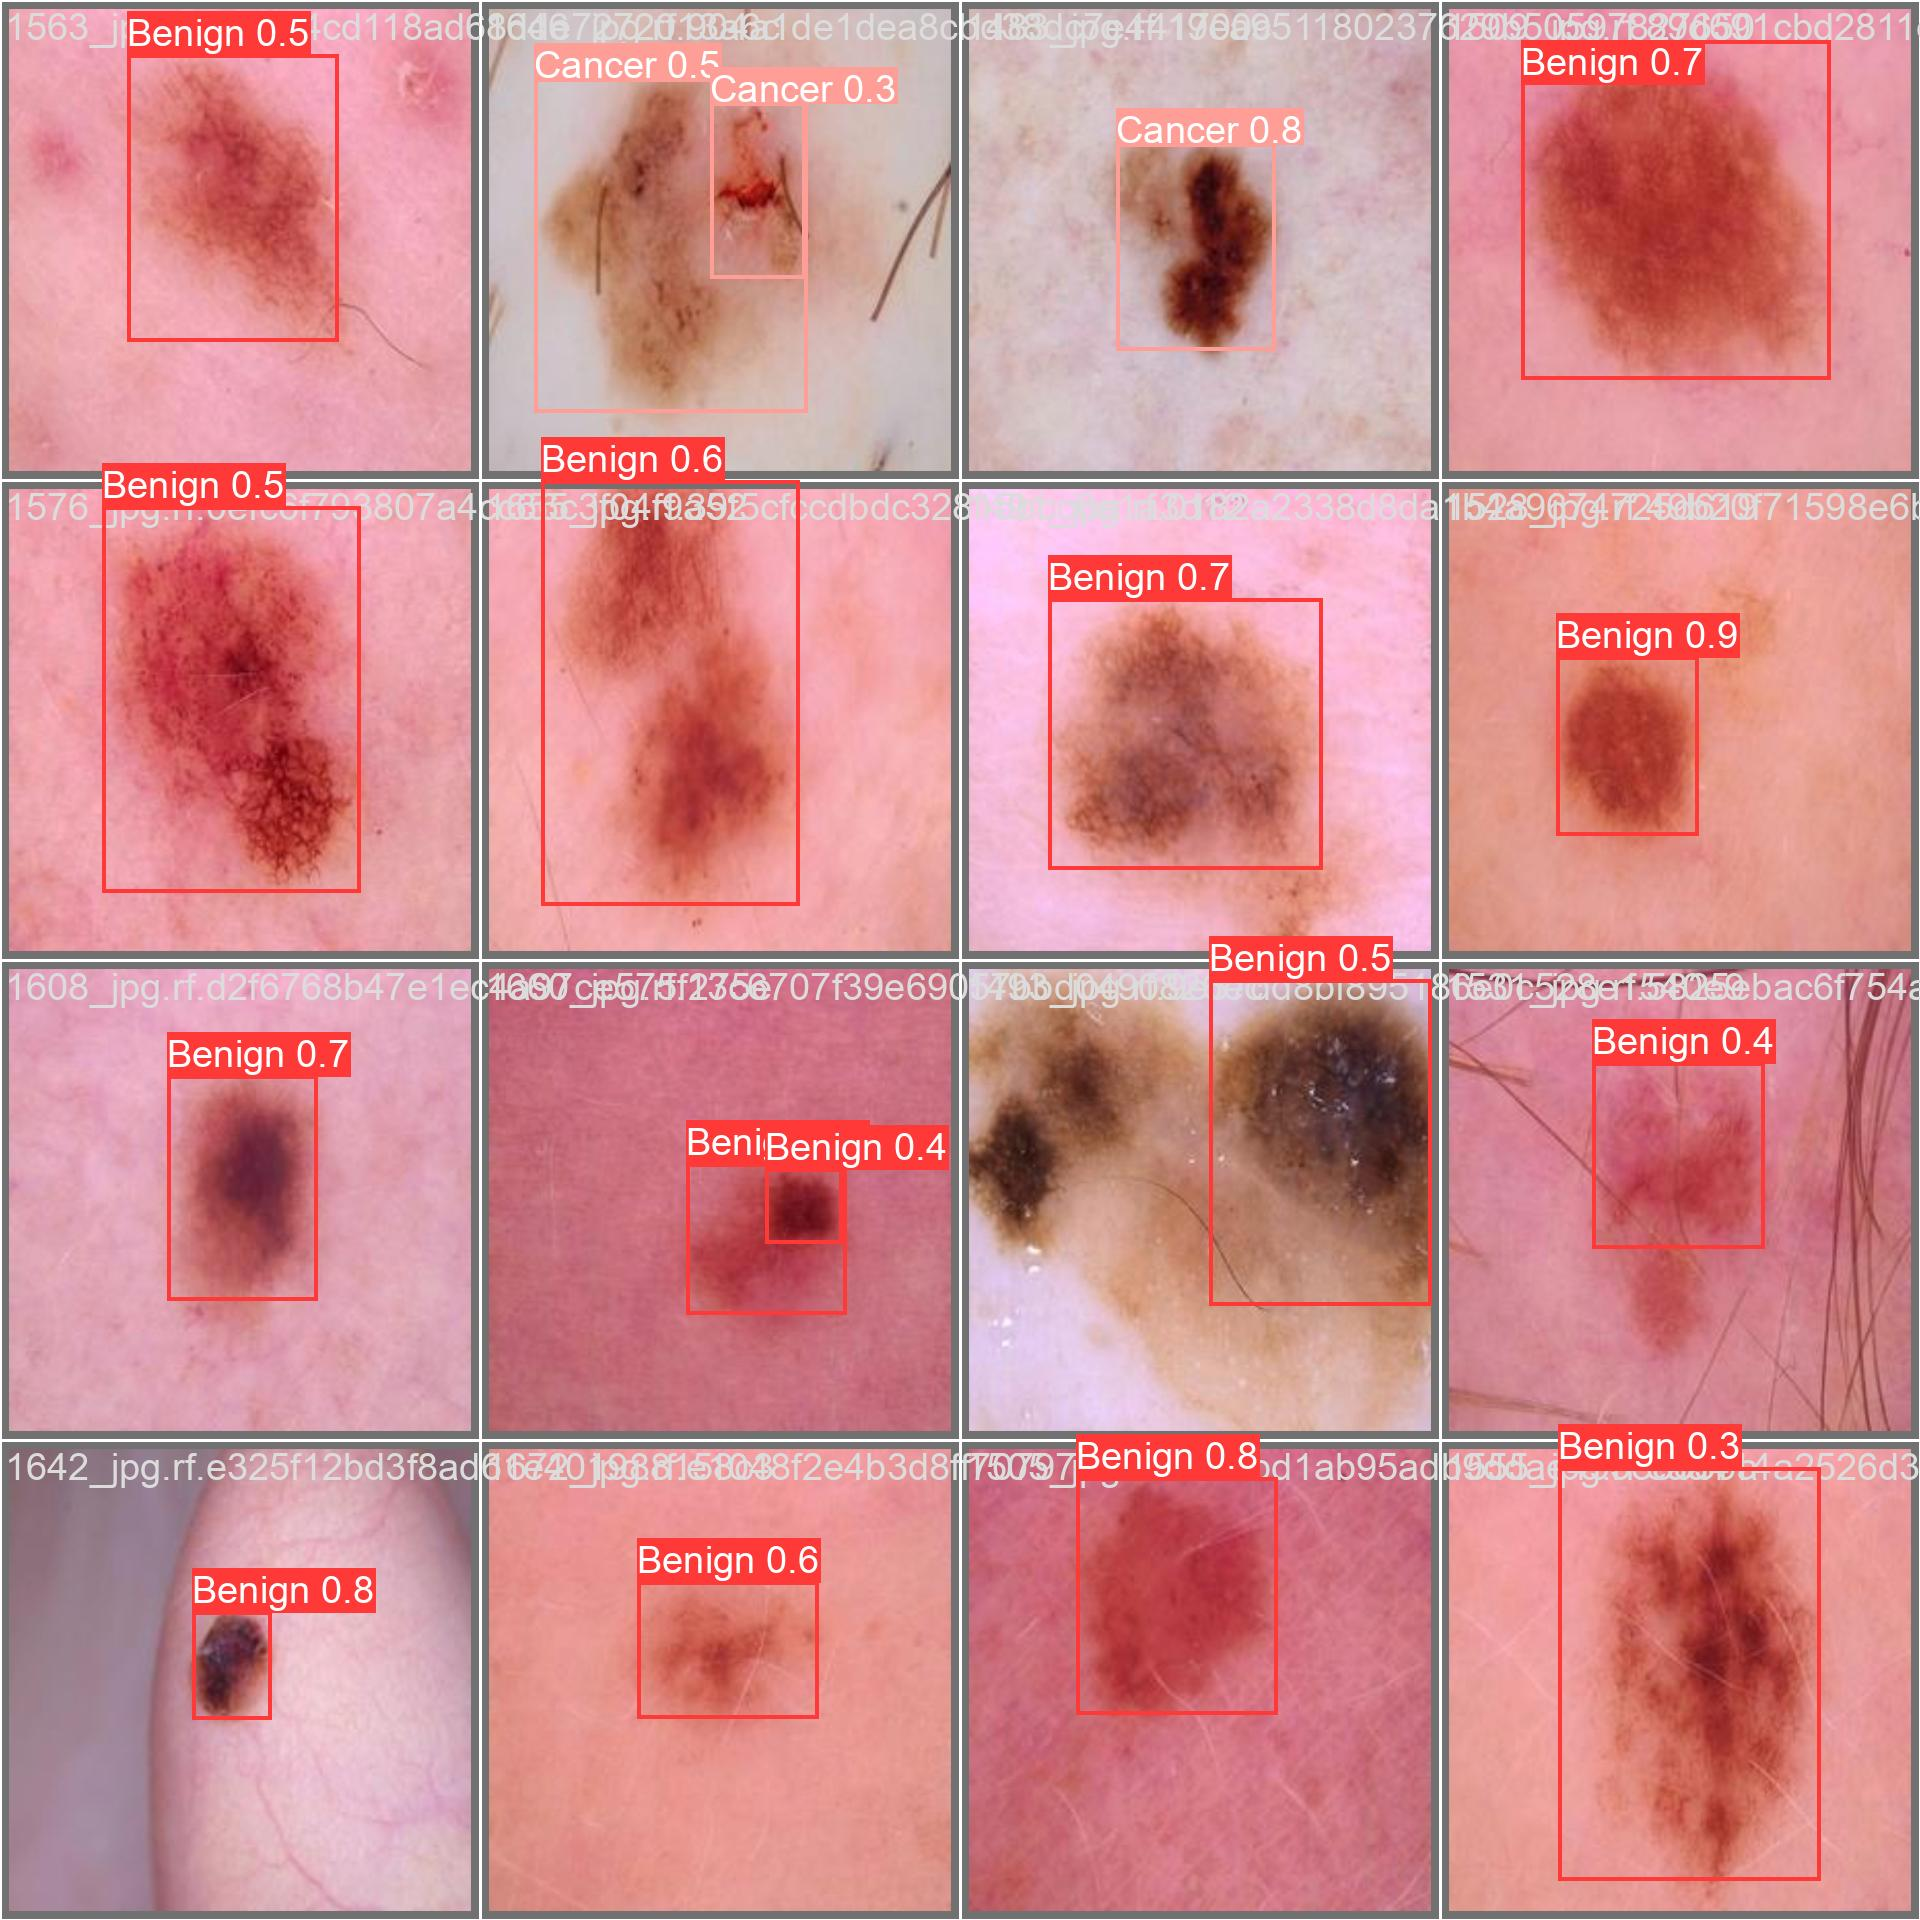

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/train/skin_cancer_yolov52/val_batch0_pred.jpg', width=600)

In [ ]:
%cd {HOME}/yolov5

!python val.py \
--weights {HOME}/runs/train/skin_cancer_yolov52/weights/best.pt \
--data /content/datasets/Skin-Cancer-1/data.yaml \
--img 800 \
--half

/content/yolov5
val: data=/content/datasets/Skin-Cancer-1/data.yaml, weights=['/content/runs/train/skin_cancer_yolov52/weights/best.pt'], batch_size=32, imgsz=800, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=True, dnn=False
YOLOv5 🚀 v7.0-467-g1d62daa3 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)

Fusing layers... 
Model summary: 157 layers, 7015519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/datasets/Skin-Cancer-1/valid/labels.cache... 400 images, 0 backgrounds, 0 corrupt: 100% 400/400 [00:00<?, ?it/s]
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% 13/13 [00:05<00:00,  2.53it/s]
                   all        400        407      0.644      0.856      0.789      0.605
                Benign        400

In [ ]:
import pandas as pd
import os
from IPython.display import display

results_path = f"{HOME}//runs/train/skin_cancer_yolov52/results.csv"

if os.path.exists(results_path):
    df = pd.read_csv(results_path)

    df.columns = [c.strip() for c in df.columns]

    last_epoch = df.iloc[-1:]

    final_table = last_epoch[['epoch', 'metrics/precision', 'metrics/recall', 'metrics/mAP_0.5', 'metrics/mAP_0.5:0.95']]

    final_table.columns = ['Epoch', 'Precision', 'Recall', 'mAP@.5', 'mAP@.5:.95']

    display(final_table)
else:
    print("Sonuç dosyası bulunamadı. Lütfen yolu kontrol et!")

,Epoch,Precision,Recall,mAP@.5,mAP@.5:.95
24,24,0.64314,0.85711,0.78849,0.60542


In [ ]:
%cd {HOME}/yolov5

!python detect.py \
--weights {HOME}/runs/train/skin_cancer_yolov52/weights/best.pt \
--conf 0.25 \
--img 800 \
--source {data['test']} \
--save-txt \
--save-conf \
--exist-ok

/content/yolov5
detect: weights=['/content/runs/train/skin_cancer_yolov52/weights/best.pt'], source=/content/datasets/Skin-Cancer-1/test/images, data=data/coco128.yaml, imgsz=[800, 800], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-467-g1d62daa3 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)

Fusing layers... 
Model summary: 157 layers, 7015519 parameters, 0 gradients, 15.8 GFLOPs
image 1/199 /content/datasets/Skin-Cancer-1/test/images/0013_jpg.rf.8a3791653d30332040cb5f9b7203f234.jpg: 800x800 1 Cancer, 6.1ms
image 2/199 /content/datasets/Skin-Cancer-1/test/images/0014_jpg.rf.9ddcdd6dd784f88b6fecdfe2b8275999.jpg: 80

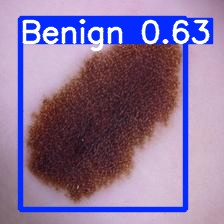

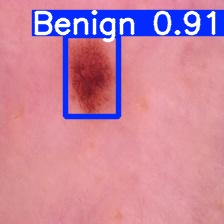

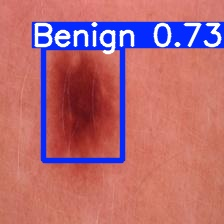

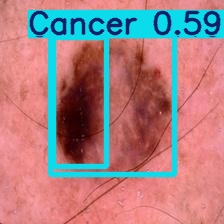

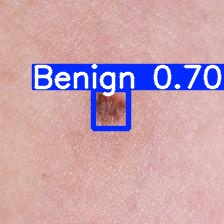

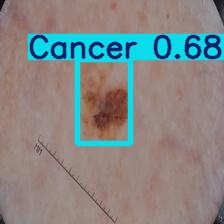

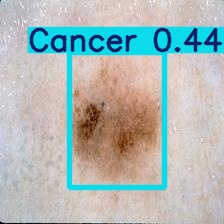

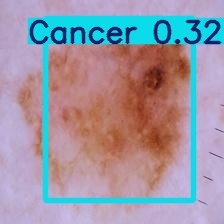

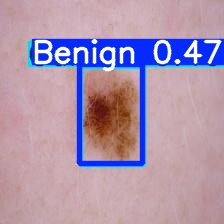

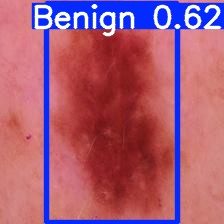

In [ ]:
import glob
from IPython.display import Image, display
import os

base_path = f'{HOME}/yolov5/runs/detect/'

subfolders = [os.path.join(base_path, d) for d in os.listdir(base_path)
              if os.path.isdir(os.path.join(base_path, d)) and d.startswith('exp')]

latest_folder = max(subfolders, key=os.path.getmtime)

image_paths = glob.glob(f'{latest_folder}/*.jpg')[:10]

for image_path in image_paths:
    display(Image(filename=image_path, width=600))
    print("\n")